# 7.1 Reranking de noticias por macrotema

Este notebook implementa un sistema de reranking con el objetivo de romper burbujas de información: dado un macrotema, devuelve una lista de artículos reordenada que garantiza que el lector ve el mismo tema desde **las tres perspectivas ideológicas** (IZQUIERDA, CENTRO, DERECHA) y desde **distintos medios**.

Sin reranking, un sistema de recomendación estándar devolvería los artículos más recientes o más populares, que suelen pertenecer a unos pocos medios alineados con la ideología. Este reranking rompe ese sesgo de forma explícita.

## Algoritmo

```
1. Cargar corpus_maestro.parquet
2. Filtrar artículos del macrotema seleccionado
3. Calcular score:  score = 0.4 × ideologia_confianza + 0.6 × recencia
4. Ordenar cada grupo ideológico por score (mejor primero)
5. Interleaving round-robin: IZQ → CEN → DER → IZQ → ...
   (la ideología de inicio rota entre sesiones para evitar sesgo de posición)
6. Post-proceso: si el mismo medio se repite en ventana de 3, desplazarlo
7. Devolver los primeros n artículos con metadatos de ranking
```

## Por qué este diseño

| Decisión | Justificación |
|---|---|
| **score lineal sin umbral** | Los artículos más ideológicamente claros (alta confianza) aparecen primero, los ambiguos al final de su grupo. Sin exclusiones para no perder representación de ideologías con pocos artículos en el macrotema. |
| **recencia pesa más (0.6)** | El objetivo es mostrar noticias actuales, no archivo histórico. |
| **round-robin, no ranking puro** | Un ranking puro devolvería solo la ideología mayoritaria del corpus. El round-robin fuerza representación igualitaria independientemente del volumen por ideología. |
| **rotación de inicio por sesión** | La posición 1 tiene más visibilidad. Sin rotación, la misma ideología siempre ocuparía las posiciones 1, 4, 7... creando un sesgo de primer lugar. |
| **penalización de medio** | Evita que el mismo medio domine posiciones consecutivas. La diversidad de fuente refuerza la diversidad ideológica. |

## 0. Configuración e imports

In [1]:
import json
import warnings
from pathlib import Path
import math

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 90)

# Rutas
DATA_FINAL    = Path('../data/final')
OUTPUT_DIR    = Path('../output')
RERANKING_DIR = OUTPUT_DIR / 'reranking'
RERANKING_DIR.mkdir(exist_ok=True)

# Orden del round-robin
IDEOLOGIAS = ['IZQUIERDA', 'CENTRO', 'DERECHA']

# Pesos del score = W_CONF × ideologia_confianza  +  W_REC × recencia
W_CONF = 0.4
W_REC  = 0.6

# Paleta de colores por ideología
COLORS_IDEO = {
    'IZQUIERDA': '#e15759',
    'CENTRO':    '#f28e2b',
    'DERECHA':   '#4e79a7',
}

# Fichero de estado de sesión (en output/, no en reranking/)
STATE_PATH = OUTPUT_DIR / 'reranking_state.json'

print('Configuración lista')
print(f'Outputs → {RERANKING_DIR.resolve()}')


Configuración lista
Outputs → /Users/blancagallardo/PycharmProjects/TFM/output/reranking


## 1. Carga del corpus maestro

El corpus maestro fue construido en `7.0_dataframe_final.ipynb`.

In [2]:
df = pd.read_parquet(DATA_FINAL / 'corpus_maestro.parquet')

df['fecha_dt'] = pd.to_datetime(df['fecha_dt'], errors='coerce')

print(f'Corpus cargado: {len(df):,} artículos × {df.shape[1]} columnas')
print(f'\nMacrotemas disponibles:')
print(df[df['macrotema'] != 'sin_clasificar']['macrotema'].value_counts().rename('artículos').to_string())
print(f'\nDistribución ideológica:')
print(df['label_ideologia'].value_counts().rename('artículos').to_string())

Corpus cargado: 240,882 artículos × 22 columnas

Macrotemas disponibles:
macrotema
politica_nacional      70771
sucesos_seguridad      37862
economia_social        36030
internacional          25813
justicia_corrupcion    25454
derechos_sociales      21624
macroeconomia          20858
tecnologia              2470

Distribución ideológica:
label_ideologia
CENTRO       100705
IZQUIERDA     83319
DERECHA       56858



## 2. Motor de reranking

El motor está formado por cuatro componentes independientes que se encadenan en `rerank_macrotema`. Se explica cada uno por separado para poder modificarlos o sustituirlos de forma aislada.

### 2.1 Score compuesto

```
score = 0.4 × ideologia_confianza  +  0.6 × recencia
```

**`ideologia_confianza`** es la probabilidad que el modelo asignó a la clase predicha (0 a 1). Un artículo con confianza 0.97 está claramente posicionado ideológicamente. Uno con 0.52 es ambiguo. Priorizar alta confianza hace que el lector vea primero los artículos donde la perspectiva es más nítida, maximizando el contraste entre posiciones y el efecto anti-burbuja.

**`recencia`** es la fecha normalizada al rango del macrotema (no del corpus global):
- artículo más reciente del macrotema → recencia = 1.0  
- artículo más antiguo del macrotema → recencia = 0.0  

Pesa más (0.6) porque el objetivo es mostrar noticias actuales.

**Sin umbral de exclusión**: artículos de baja confianza no se eliminan, solo puntúan menos y quedan al final de su grupo ideológico. Esto garantiza representación de todas las ideologías incluso cuando una tiene pocos artículos sobre el macrotema.

In [3]:
def calcular_scores(
    df_macro: pd.DataFrame,
    w_conf: float = W_CONF,
    w_rec:  float = W_REC,
) -> pd.Series:
    """
    score = w_conf × ideologia_confianza  +  w_rec × recencia_normalizada
    La recencia se normaliza al rango de fechas del propio macrotema.
    """
    confianza    = df_macro['ideologia_confianza'].fillna(0.0)
    fechas       = df_macro['fecha_dt']
    f_min, f_max = fechas.min(), fechas.max()

    if pd.isna(f_min) or pd.isna(f_max) or f_max == f_min:
        recencia = pd.Series(0.5, index=df_macro.index)
    else:
        recencia = (fechas - f_min) / (f_max - f_min)

    return (w_conf * confianza + w_rec * recencia).rename('score')

### 2.2 Round-robin por ideología

El round-robin es el núcleo del bubble-breaking. En lugar de una lista puramente por score (que daría la ideología mayoritaria del corpus), toma el mejor artículo de cada grupo en rotación:

```
pos 1 → mejor IZQUIERDA  (por score)
pos 2 → mejor CENTRO
pos 3 → mejor DERECHA
pos 4 → 2º IZQUIERDA
pos 5 → 2º CENTRO
...
```

Si un grupo se agota (p. ej. CENTRO tiene pocos artículos sobre este macrotema), sus slots los absorben los demás grupos sin romper el ciclo.

El campo `rank_ideologia` indica la posición del artículo **dentro de su grupo** antes del interleaving: `rank_ideologia=1` es el mejor artículo de esa ideología para el macrotema.

In [4]:
def interleave_ideologias(df_scored: pd.DataFrame, start: str) -> list:
    """
    Intercala artículos en round-robin por ideología.

    Parámetros
    ----------
    df_scored : DataFrame con columnas 'label_ideologia' y 'score'
    start     : ideología que ocupa la posición 1

    Devuelve
    --------
    Lista de dicts con los artículos intercalados + 'rank_ideologia'.
    """
    idx   = IDEOLOGIAS.index(start)
    orden = IDEOLOGIAS[idx:] + IDEOLOGIAS[:idx]

    grupos = {
        ideo: df_scored[df_scored['label_ideologia'] == ideo]
              .sort_values('score', ascending=False)
              .to_dict('records')
        for ideo in orden
    }

    contadores = {ideo: 0 for ideo in orden}
    result     = []

    while any(grupos[i] for i in orden):
        for ideo in orden:
            if grupos[ideo]:
                art = grupos[ideo].pop(0)
                contadores[ideo]    += 1
                art['rank_ideologia'] = contadores[ideo]
                result.append(art)

    return result

### 2.3 Penalización de medio repetido

Tras el round-robin ideológico puede ocurrir que el mismo medio aparezca en posiciones consecutivas. Por ejemplo, si El País y elDiario tienen muchos artículos de IZQUIERDA, las posiciones 1, 4, 7... pueden ser alternadamente El País / elDiario. La diversidad ideológica está garantizada pero no la de fuente.

Este paso recorre la lista y, si el medio del siguiente artículo ya aparece en las últimas `ventana` posiciones, lo intercambia con el siguiente artículo disponible de un medio diferente. Con `ventana=3`: el mismo medio no puede aparecer dos veces en 3 posiciones seguidas.

#### Trade-off conocido: diversidad de medio vs patrón ideológico

Al mover un artículo para evitar un medio repetido, **se arrastra su ideología** a una posición diferente. Esto puede romper el patrón visual del round-robin y hacer que dos artículos de la misma ideología aparezcan juntos:

```
Round-robin (perfecto):   IZQ · CEN · DER · IZQ · CEN · DER
                                               ↕ swap por medio
Tras diversidad de medio: IZQ · CEN · DER · CEN · IZQ · DER  ← dos CEN juntas
```

Hay una segunda causa: si una ideología tiene muy pocos artículos sobre el macrotema y se agota antes que las otras, sus slots los absorben las ideologías restantes, que entonces aparecen consecutivas:

```
CENTRO agotado: IZQ · CEN · DER · IZQ · DER · IZQ · DER
                                        ↑ no hay más CEN
```

**Decisión de diseño**: se prioriza la diversidad de medio sobre la regularidad visual del patrón ideológico. La entropía de Shannon (H) del resultado sigue siendo alta y la diversidad real no se pierde, solo el patrón visual no es perfectamente alternado. Esta limitación se documenta y cuantifica en la sección de métricas.

In [5]:
def aplicar_diversidad_medio(articulos: list, ventana: int = 3) -> list:
    """
    Evita que el mismo medio aparezca más de una vez en `ventana` posiciones.

    Greedy: busca el primer artículo pendiente cuyo medio no esté en la
    ventana reciente. Si no hay alternativa, deja pasar el artículo actual.
    """
    result     = []
    pendientes = list(articulos)

    while pendientes:
        medios_recientes = {a['medio'] for a in result[-ventana:]}
        idx_elegido = next(
            (i for i, a in enumerate(pendientes) if a['medio'] not in medios_recientes),
            0  # fallback si todos los medios restantes están en la ventana
        )
        result.append(pendientes.pop(idx_elegido))

    return result

### 2.4 Estado de sesión (rotación de ideología de inicio)

La posición 1 tiene más visibilidad que las posiciones 4 o 7. Si la misma ideología siempre arranca el round-robin, sus artículos ocupan sistemáticamente las posiciones 1, 4, 7, 10... lo que introduce un sesgo de primer lugar.

Guardamos en `output/reranking_state.json` la ideología que arrancó la última sesión **por macrotema** y rotamos:

```
sesión 1 (politica_nacional) → empieza IZQUIERDA  
sesión 2 (politica_nacional) → empieza CENTRO  
sesión 3 (politica_nacional) → empieza DERECHA  
sesión 4 (politica_nacional) → empieza IZQUIERDA  ...
```

El estado es **independiente por macrotema**: si el usuario consulta `economia_social` y luego `politica_nacional`, cada uno avanza su propia rotación sin afectar al otro. El JSON tiene la forma:

```json
{
  "economia_social":   {"last_start": "DERECHA",    "session_n": 5},
  "politica_nacional": {"last_start": "IZQUIERDA",  "session_n": 3}
}
```

Si un macrotema no tiene historial, se inicializa en `last_start = "DERECHA"`

In [6]:
def cargar_estado(macrotema: str) -> dict:
    """Carga el estado de sesión para un macrotema concreto.
    Si el fichero o el macrotema no existen, inicializa en DERECHA.
    """
    if STATE_PATH.exists():
        todos = json.loads(STATE_PATH.read_text(encoding='utf-8'))
    else:
        todos = {}
    return todos.get(macrotema, {'last_start': 'DERECHA', 'session_n': 0})

def guardar_estado(macrotema: str, estado: dict) -> None:
    """Persiste el estado de un macrotema sin sobreescribir los demás."""
    if STATE_PATH.exists():
        todos = json.loads(STATE_PATH.read_text(encoding='utf-8'))
    else:
        todos = {}
    todos[macrotema] = estado
    STATE_PATH.write_text(
        json.dumps(todos, indent=2, ensure_ascii=False),
        encoding='utf-8'
    )

def siguiente_inicio(estado: dict) -> str:
    """Devuelve la ideología de inicio para esta sesión (rota cíclicamente)."""
    idx = IDEOLOGIAS.index(estado['last_start'])
    return IDEOLOGIAS[(idx + 1) % 3]

# Mostrar estado actual de todos los macrotemas
if STATE_PATH.exists():
    todos = json.loads(STATE_PATH.read_text(encoding='utf-8'))
    if todos and isinstance(next(iter(todos.values())), dict):
        print('Estado actual por macrotema:')
        for mt, est in sorted(todos.items()):
            print(f'  {mt:<28} last_start={est["last_start"]:<12}  session_n={est["session_n"]}')
    else:
        print('Estado en formato antiguo (global) — se reiniciará al primer uso')
else:
    print('Sin estado guardado — primera ejecución')

Sin estado guardado — primera ejecución


### 2.5 Función principal: `rerank_macrotema`

Encadena los cuatro componentes anteriores. El parámetro `avanzar_sesion=True` actualiza el fichero de estado para que la próxima sesión empiece con la siguiente ideología en la rotación. Se puede poner a `False` durante exploración para no consumir la rotación.

In [7]:
def rerank_macrotema(
    df_maestro:     pd.DataFrame,
    macrotema:      str,
    n:              int   = 30,
    w_conf:         float = W_CONF,
    w_rec:          float = W_REC,
    ventana_medio:  int   = 3,
    avanzar_sesion: bool  = True,
) -> pd.DataFrame:
    """
    Devuelve los `n` artículos del macrotema reordenados para romper burbujas.

    Campos añadidos al resultado
    ----------------------------
    pos                     : posición final (1 = primero)
    score                   : score compuesto
    score_confianza         : componente de confianza ideológica
    score_recencia          : componente de recencia
    rank_ideologia          : posición dentro del grupo ideológico antes del interleaving
    ideologia_inicio_sesion : ideología que arrancó el round-robin esta sesión
    """
    # Filtrar por macrotema con ideología y fecha válidas
    df_macro = df_maestro[
        (df_maestro['macrotema'] == macrotema) &
        df_maestro['label_ideologia'].notna() &
        df_maestro['fecha_dt'].notna()
    ].copy()

    if df_macro.empty:
        raise ValueError(f'No hay artículos para el macrotema "{macrotema}"')

    # Score compuesto + componentes por separado (para transparencia)
    df_macro['score']           = calcular_scores(df_macro, w_conf, w_rec)
    df_macro['score_confianza'] = df_macro['ideologia_confianza'].fillna(0.0)

    fechas = df_macro['fecha_dt']
    f_min, f_max = fechas.min(), fechas.max()
    df_macro['score_recencia'] = (
        (fechas - f_min) / (f_max - f_min)
        if f_max != f_min
        else pd.Series(0.5, index=df_macro.index)
    )

    # Ideología de inicio de esta sesión (estado independiente por macrotema)
    estado = cargar_estado(macrotema)
    inicio = siguiente_inicio(estado)

    # Round-robin por ideología
    articulos_rr = interleave_ideologias(df_macro, start=inicio)

    # Penalización de medio repetido
    articulos_div = aplicar_diversidad_medio(articulos_rr, ventana=ventana_medio)

    # Resultado final
    resultado = pd.DataFrame(articulos_div[:n])
    resultado.insert(0, 'pos', range(1, len(resultado) + 1))
    resultado['ideologia_inicio_sesion'] = inicio

    # Actualizar estado del macrotema
    if avanzar_sesion:
        estado['last_start'] = inicio
        estado['session_n']  = estado.get('session_n', 0) + 1
        guardar_estado(macrotema, estado)

    return resultado

## 3. Demo (reranking de un macrotema)

Probamos con `economia_social`. `avanzar_sesion=False` para no consumir la rotación durante la exploración.

In [8]:
MACROTEMA_DEMO = 'economia_social'

resultado_demo = rerank_macrotema(df, MACROTEMA_DEMO, n=20, avanzar_sesion=False)

inicio_demo = resultado_demo['ideologia_inicio_sesion'].iloc[0]
print(f'Macrotema           : {MACROTEMA_DEMO}')
print(f'Ideología de inicio : {inicio_demo}')
print(f'Artículos devueltos : {len(resultado_demo)}')
print(f'\nDistribución ideológica en el top-{len(resultado_demo)}:')
print(resultado_demo['label_ideologia'].value_counts().to_string())
print(f'\nDistribución por medio:')
print(resultado_demo['medio'].value_counts().to_string())


Macrotema           : economia_social
Ideología de inicio : IZQUIERDA
Artículos devueltos : 20

Distribución ideológica en el top-20:
label_ideologia
IZQUIERDA    10
DERECHA       7
CENTRO        3

Distribución por medio:
medio
El País            5
OKDiario           5
El Mundo           5
Público            4
El Confidencial    1


#### Por qué el resultado es 10 IZQ · 3 CEN · 7 DER

El round-robin puro con inicio IZQUIERDA produciría 7 IZQ · 7 CEN · 6 DER. La distribución real difiere por el **post-proceso de diversidad de medio**: `economia_social` incluye temas como empleo, pensiones y vivienda, áreas donde El País (CENTRO) tiene una cobertura muy densa. Sus artículos de alta recencia se acumulan en el top del grupo CENTRO, y el filtro greedy los desplaza repetidamente al detectar que El País ya aparece en la ventana de 3 posiciones. Los huecos que dejan los artículos CENTRO desplazados los ocupan artículos IZQ o DER de otros medios, que entonces superan el corte de los 20.

 elDiario no aparece, a pesar de ser un medio de izquierda, sus artículos de `economia_social` tienen scores más bajos (menor recencia o menor confianza ideológica) que los de Público o El Mundo en este macrotema, por lo que quedan fuera del top-20 incluso tras el reranking.

Cabe destacar que la ideología de inicio es IZQUIERDA porque el estado de sesión partía de `last_start = DERECHA` (sin historial previo), por lo que `siguiente_inicio` devuelve IZQUIERDA.

In [9]:
cols_show = [
    'pos', 'medio', 'url', 'titular', 'fecha',
    'nombre_topic', 'label_ideologia', 'ideologia_confianza',
    'score', 'score_recencia', 'score_confianza',
    'rank_ideologia', 'ideologia_inicio_sesion'
]

with pd.option_context('display.max_colwidth', 70, 'display.max_rows', 25):
    display(
        resultado_demo[cols_show]
        .style.background_gradient(subset=['score'], cmap='YlOrRd')
        .bar(subset=['ideologia_confianza'], color='#d4e6f1')
    )


,pos,medio,url,titular,fecha,nombre_topic,label_ideologia,ideologia_confianza,score,score_recencia,score_confianza,rank_ideologia,ideologia_inicio_sesion
0,1,El País,https://elpais.com/opinion/2026-04-07/bajas-laborales-sin-solucion.html,Bajas laborales sin solución,2026-04-07T05:30:01,empleo_pensiones,IZQUIERDA,1.000000,0.998751,0.997918,1.000000,1,IZQUIERDA
1,2,OKDiario,https://okdiario.com/economia/ponen-prueba-producto-viral-mercadona-dejar-ollas-como-nuevas-esto-lo-que-pasa-11660683,Ponen a prueba el producto viral de Mercadona para dejar las ollas como nuevas y esto es lo que pasa,2026-04-09T13:30:32,consumo_precios,CENTRO,1.000000,1.000000,1.000000,1.000000,1,IZQUIERDA
2,3,El Mundo,https://www.elmundo.es/opinion/editorial/2026/04/04/69cfafbffc6c83da658b45bb.html,La factura de la guerra de Irán,2026-04-03T22:12:02,inflacion_precios,DERECHA,1.000000,0.996983,0.994971,1.000000,2,IZQUIERDA
3,4,Público,https://www.publico.es/politica/gobierno/consejo-posiciona-reforma-registro-horario-impulsada-trabajo.html,El Consejo de Estado se posiciona en contra de la reforma del registro horario impulsada por Trabajo,2026-03-24T08:39:36,empleo_pensiones,DERECHA,0.999500,0.991129,0.985548,0.999500,16,IZQUIERDA
4,5,El País,https://elpais.com/opinion/2026-04-05/la-tension-permanente-no-es-inevitable.html,La tensión permanente no es inevitable,2026-04-05T05:30:01,inflacion_precios,IZQUIERDA,1.000000,0.997681,0.996134,1.000000,2,IZQUIERDA
5,6,OKDiario,https://okdiario.com/economia/pisos-alquiler-tienen-dias-contados-espana-gonzalo-bernardos-lo-confirmado-propietarios-estan-hartos-16489265,Gonzalo Bernardos confirma que los pisos de alquiler tienen los días contados: «Los propietarios están hartos»,2026-04-04T11:01:40,vivienda_alquiler,DERECHA,1.000000,0.997269,0.995448,1.000000,1,IZQUIERDA
6,7,El Mundo,https://www.elmundo.es/opinion/columnistas/2026/04/03/69ce896e21efa000418b45b2.html,"Perdona, llevas el bolso abierto",2026-04-02T22:06:44,consumo_precios,IZQUIERDA,0.995600,0.994685,0.994076,0.995600,7,IZQUIERDA
7,8,Público,https://www.publico.es/politica/diaz-echa-pulso-cuerpo-llevara-consejo-ministros-registro-horario-pese-criticas-consejo.html,Díaz echa un pulso a Cuerpo y llevará al Consejo de Ministros su registro horario pese a las críticas del Consejo de Estado,2026-03-24T21:55:00,empleo_pensiones,IZQUIERDA,1.000000,0.991624,0.986041,1.000000,27,IZQUIERDA
8,9,El País,https://elpais.com/economia/2026-04-02/los-superricos-poseen-el-80-de-la-fortuna-que-se-oculta-en-refugios-fiscales.html,Los superricos poseen el 80% de la fortuna que se oculta en refugios fiscales,2026-04-02T11:50:35,fiscalidad_hacienda,IZQUIERDA,1.000000,0.996216,0.993694,1.000000,3,IZQUIERDA
9,10,OKDiario,https://okdiario.com/economia/que-significa-cuando-sale-negativo-declaracion-renta-12633732,Hacienda lo confirma: qué significa cuando sale negativo en tu declaración de la Renta,2026-04-08T13:44:49,fiscalidad_hacienda,CENTRO,1.000000,0.999470,0.999117,1.000000,2,IZQUIERDA



## 4. Comparativa: baseline vs reranking

Para demostrar que el reranking mejora la diversidad ideológica, no solo que la produce comparamos dos listas del mismo macrotema:

- **Baseline**: top-20 puramente por score, sin ningún control de diversidad. Simula lo que devolvería un sistema de recomendación estándar.
- **Reranking**: la lista con round-robin + penalización de medio.

Si el baseline concentra artículos en una o dos ideologías y el reranking las distribuye de forma más equitativa, queda demostrado el efecto anti-burbuja.

In [10]:
def ranking_baseline(df_maestro: pd.DataFrame, macrotema: str, n: int = 20) -> pd.DataFrame:
    """
    Ranking sin control de diversidad: top-n por score descendente.
    Simula un sistema de recomendación estándar que no tiene en cuenta
    la ideología ni el medio.
    """
    df_macro = df_maestro[
        (df_maestro['macrotema'] == macrotema) &
        df_maestro['label_ideologia'].notna() &
        df_maestro['fecha_dt'].notna()
    ].copy()

    df_macro['score'] = calcular_scores(df_macro)
    resultado = df_macro.nlargest(n, 'score').reset_index(drop=True)
    resultado.insert(0, 'pos', range(1, len(resultado) + 1))
    return resultado


In [11]:
baseline_demo = ranking_baseline(df, MACROTEMA_DEMO, n=20)

# Distribución ideológica comparada
cnt_base    = baseline_demo['label_ideologia'].value_counts()
cnt_rerank  = resultado_demo['label_ideologia'].value_counts()
cnt_corpus  = df[df['macrotema'] == MACROTEMA_DEMO]['label_ideologia'].value_counts(normalize=True).mul(100).round(1)

df_comp = pd.DataFrame({
    'Corpus (%)':   cnt_corpus,
    'Baseline':     cnt_base,
    'Reranking':    cnt_rerank,
}).reindex(IDEOLOGIAS).fillna(0).astype({'Baseline': int, 'Reranking': int})

print(f'=== Comparativa ideológica — {MACROTEMA_DEMO} ===')
print(df_comp.to_string())
print(f'\nBaseline  — medio dominante: {baseline_demo["medio"].value_counts().index[0]} '
      f'({baseline_demo["medio"].value_counts().iloc[0]} de 20 artículos)')
print(f'Reranking — medio dominante: {resultado_demo["medio"].value_counts().index[0]} '
      f'({resultado_demo["medio"].value_counts().iloc[0]} de 20 artículos)')


=== Comparativa ideológica — economia_social ===
                 Corpus (%)  Baseline  Reranking
label_ideologia                                 
IZQUIERDA              26.2         4         10
CENTRO                 61.1        14          3
DERECHA                12.7         2          7

Baseline  — medio dominante: El País (10 de 20 artículos)
Reranking — medio dominante: El País (5 de 20 artículos)


El baseline refleja fielmente la distribución del corpus: como el 61% de los artículos de `economia_social` son CENTRO, el top-20 por score devuelve 14 CENTRO. Un lector que usara este sistema leería casi exclusivamente una perspectiva, que es la definición de burbuja informativa. El medio dominante (El País) ocupa 10 de los 20 puestos, concentrando además la fuente.

El reranking rompe ambos sesgos a la vez: fuerza presencia de las tres ideologías mediante round-robin y limita la repetición de medio con la ventana de 3. El resultado es que El País pasa de 10 a 5 artículos y las tres ideologías están representadas, aunque la distribución no sea perfectamente uniforme por el trade-off con la diversidad de medio documentado en la sección 2.3.

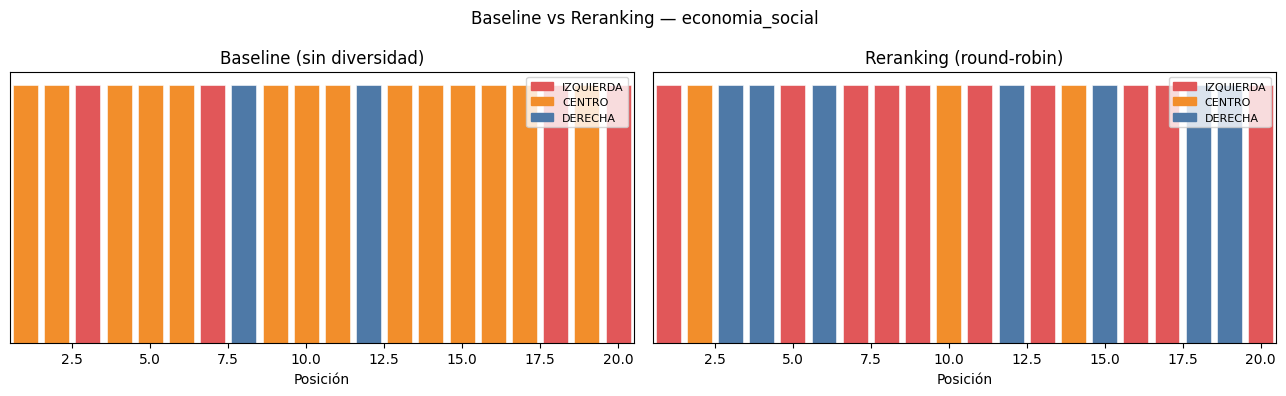

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(f'Baseline vs Reranking — {MACROTEMA_DEMO}', fontsize=12)

leyenda = [mpatches.Patch(color=c, label=i) for i, c in COLORS_IDEO.items()]

for ax, df_plot, titulo in [
    (axes[0], baseline_demo,  'Baseline (sin diversidad)'),
    (axes[1], resultado_demo, 'Reranking (round-robin)'),
]:
    colors_pos = [COLORS_IDEO.get(i, '#aaa') for i in df_plot['label_ideologia']]
    ax.bar(df_plot['pos'], 1, color=colors_pos, edgecolor='white', linewidth=0.4)
    ax.set_xlabel('Posición')
    ax.set_title(titulo)
    ax.set_yticks([])
    ax.set_xlim(0.5, len(df_plot) + 0.5)
    ax.legend(handles=leyenda, fontsize=8)

plt.tight_layout()
plt.savefig(RERANKING_DIR / f'comparativa_baseline_{MACROTEMA_DEMO}.png',
            dpi=150, bbox_inches='tight')
plt.show()


## 5. Visualización del reranking

Tres gráficos para verificar el resultado del reranking:
1. **Ideología por posición** — debe verse el patrón round-robin
2. **Artículos por medio** — ningún medio debe dominar
3. **Score por posición** — el score decrece suavemente, no en escalón


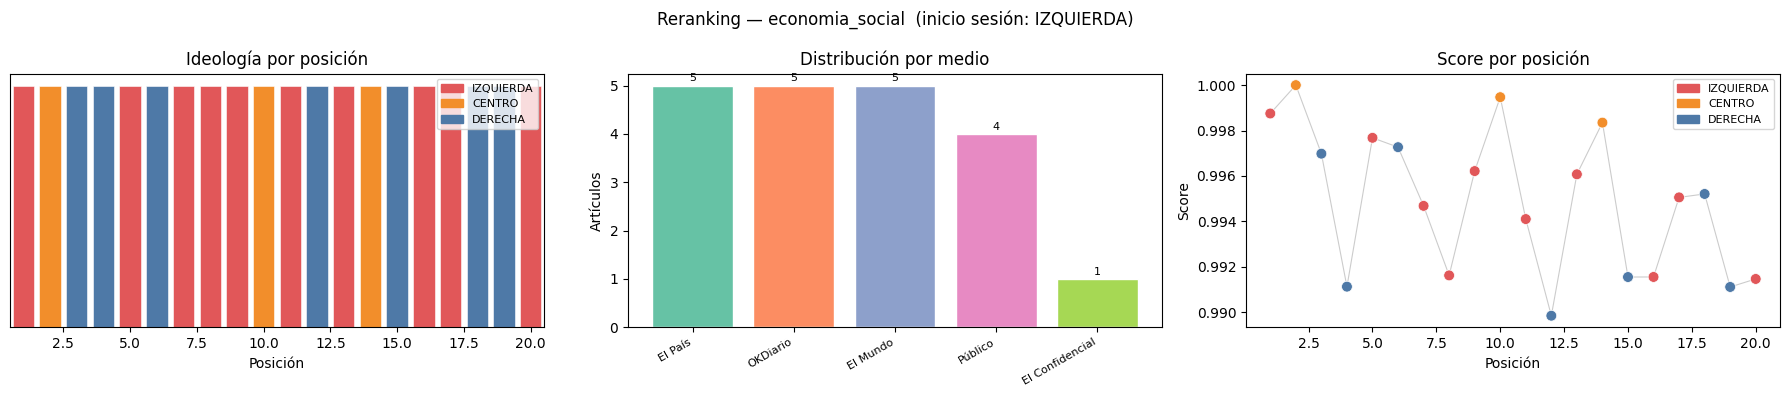

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle(f'Reranking — {MACROTEMA_DEMO}  (inicio sesión: {inicio_demo})', fontsize=12)

leyenda = [mpatches.Patch(color=c, label=i) for i, c in COLORS_IDEO.items()]

#Ideología por posición
ax = axes[0]
colors_pos = [COLORS_IDEO.get(i, '#aaa') for i in resultado_demo['label_ideologia']]
ax.bar(resultado_demo['pos'], 1, color=colors_pos, edgecolor='white', linewidth=0.4)
ax.set_xlabel('Posición')
ax.set_title('Ideología por posición')
ax.set_yticks([])
ax.set_xlim(0.5, len(resultado_demo) + 0.5)
ax.legend(handles=leyenda, fontsize=8)

# Artículos por medio
ax = axes[1]
medio_counts = resultado_demo['medio'].value_counts()
bars = ax.bar(medio_counts.index, medio_counts.values,
              color=sns.color_palette('Set2', len(medio_counts)), edgecolor='white')
ax.set_xticklabels(medio_counts.index, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Artículos')
ax.set_title('Distribución por medio')
for bar, val in zip(bars, medio_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            str(val), ha='center', va='bottom', fontsize=8)

# Score por posición
ax = axes[2]
ax.scatter(resultado_demo['pos'], resultado_demo['score'],
           c=[COLORS_IDEO.get(i, '#aaa') for i in resultado_demo['label_ideologia']],
           s=60, edgecolors='white', linewidths=0.5, zorder=3)
ax.plot(resultado_demo['pos'], resultado_demo['score'], color='#ccc', linewidth=0.8, zorder=2)
ax.set_xlabel('Posición')
ax.set_ylabel('Score')
ax.set_title('Score por posición')
ax.legend(handles=leyenda, fontsize=8)

plt.tight_layout()
plt.savefig(RERANKING_DIR / f'reranking_{MACROTEMA_DEMO}.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Métricas de diversidad

Para evaluar cuantitativamente el efecto anti-burbuja usamos dos métricas complementarias.

### Entropía de Shannon (H)

Mide cuánta incertidumbre hay sobre la ideología de un artículo elegido al azar del resultado. Intuitivamente: **¿puedes predecir la ideología del siguiente artículo?**

| Distribución (top-20) | H | Interpretación |
|---|---|---|
| 20 · 0 · 0 (solo IZQUIERDA) | 0.000 | burbuja total — siempre aciertas |
| 14 · 4 · 2 | ≈ 1.15 | burbuja parcial — predomina una ideología |
| 7 · 7 · 6 (casi igual) | ≈ 1.58 | máxima diversidad — no puedes predecir |

**Máximo teórico**: `H_max = log2(3) ≈ 1.585 bits` se alcanza cuando las tres ideologías tienen exactamente la misma probabilidad.

La fórmula es `H = -Σ pᵢ · log₂(pᵢ)` donde `pᵢ` es la proporción de cada ideología. Los valores negativos y el logaritmo hacen que distribuciones desiguales den H bajo y distribuciones equilibradas den H alto.

### Coverage

Fracción de ideologías presentes en el resultado:
- **Coverage = 1.0**: las 3 ideologías tienen al menos un artículo → burbuja rota
- **Coverage < 1.0**: alguna ideología está ausente del resultado

Coverage = 1.0 es condición necesaria pero no suficiente: puedes tener 18 IZQ + 1 CEN + 1 DER con coverage = 1.0 pero H muy bajo.

### Simulación de sesiones consecutivas

La rotación de ideología de inicio garantiza que, a lo largo de múltiples sesiones, el **balance acumulado** converja hacia H = 1.585. Simulamos 5 consultas consecutivas sobre el mismo macrotema y medimos cómo evoluciona H sobre la distribución acumulada.

La hipótesis es que H acumulado converge rápidamente hacia 1.585 porque tras 3 sesiones cada ideología ha arrancado exactamente una vez — compensando el sesgo de primer lugar.

In [14]:
def shannon_entropy(counts: pd.Series) -> float:
    """
    Entropía de Shannon en bits (base 2).
    Máximo teórico para 3 clases equiprobables: log2(3) ≈ 1.585
    """
    total = counts.sum()
    if total == 0:
        return 0.0
    probs = counts[counts > 0] / total
    return float(-sum(p * math.log2(p) for p in probs))


def coverage(resultado: pd.DataFrame, ideologias: list = IDEOLOGIAS) -> float:
    """
    Fracción de ideologías presentes en el resultado.
    1.0 = las 3 ideologías tienen al menos un artículo.
    """
    presentes = set(resultado['label_ideologia'].dropna().unique())
    return len(presentes & set(ideologias)) / len(ideologias)


H_MAX = math.log2(len(IDEOLOGIAS))  # 1.585 para 3 clases
print(f'H máximo teórico (3 clases equiprobables): {H_MAX:.4f} bits')


H máximo teórico (3 clases equiprobables): 1.5850 bits


In [15]:
# Calcular métricas para baseline y reranking del macrotema demo
cnt_base   = baseline_demo['label_ideologia'].value_counts().reindex(IDEOLOGIAS, fill_value=0)
cnt_rerank = resultado_demo['label_ideologia'].value_counts().reindex(IDEOLOGIAS, fill_value=0)

h_base    = shannon_entropy(cnt_base)
h_rerank  = shannon_entropy(cnt_rerank)
cov_base  = coverage(baseline_demo)
cov_rerank = coverage(resultado_demo)

print(f'=== Métricas de diversidad — {MACROTEMA_DEMO} ===')
print(f'\n{"":20s} {"Baseline":>12} {"Reranking":>12} {"Máximo":>10}')
print('-' * 58)
print(f'{"Entropía H (bits)":20s} {h_base:>12.4f} {h_rerank:>12.4f} {H_MAX:>10.4f}')
print(f'{"H / H_max (%%)":20s} {h_base/H_MAX*100:>11.1f}%% {h_rerank/H_MAX*100:>11.1f}%% {100:>9}%%')
print(f'{"Coverage":20s} {cov_base:>12.2f} {cov_rerank:>12.2f} {1.0:>10.2f}')
print(f'\nDistribución ideológica:')
df_dist = pd.DataFrame({'Baseline': cnt_base, 'Reranking': cnt_rerank})
print(df_dist.to_string())


=== Métricas de diversidad — economia_social ===

                         Baseline    Reranking     Máximo
----------------------------------------------------------
Entropía H (bits)          1.1568       1.4406     1.5850
H / H_max (%%)              73.0%%        90.9%%       100%%
Coverage                     1.00         1.00       1.00

Distribución ideológica:
                 Baseline  Reranking
label_ideologia                     
IZQUIERDA               4         10
CENTRO                 14          3
DERECHA                 2          7


El sistema de reranking eleva la entropía de Shannon de 1.16 bits (73% del máximo) a 1.44 bits (91%), reduciendo a la mitad el déficit respecto al máximo teórico. El baseline refleja la distribución natural del corpus donde CENTRO domina con 14 de 20 artículos porque el 61% de los artículos de este macrotema pertenecen a esa ideología y un lector que lo usara quedaría expuesto casi exclusivamente a una perspectiva.

El reranking rompe ese sesgo forzando representación de las tres ideologías mediante round-robin, logrando coverage = 1.0 (las tres ideologías presentes) en ambos casos, pero con una distribución mucho más equilibrada. La diferencia entre el 91% obtenido y el 100% teórico se debe al post-proceso de diversidad de medio, que desplaza artículos CENTRO (concentrados en El País) beneficiando en este caso a IZQUIERDA y DERECHA.

### 6.1 Simulación de sesiones consecutivas

Simulamos 5 consultas consecutivas sobre `economia_social` con `avanzar_sesion=True`. En cada sesión una ideología distinta ocupa la posición 1 (rotación cíclica). Medimos:
- H de la sesión individual
- H sobre la **distribución acumulada** de todas las sesiones hasta ese momento

La hipótesis es que H acumulado converge rápidamente hacia 1.585 porque tras 3 sesiones cada ideología ha arrancado exactamente una vez.

In [16]:
N_SESIONES   = 5
N_RESULTADO  = 20

# Guardar estado real para restaurarlo después
estado_real = cargar_estado(MACROTEMA_DEMO)

# Iniciar simulación desde cero (última start = DERECHA → primera sesión = IZQUIERDA)
guardar_estado(MACROTEMA_DEMO, {'last_start': 'DERECHA', 'session_n': 0})

registros   = []       # resultados por sesión
acumulado   = {i: 0 for i in IDEOLOGIAS}

for s in range(1, N_SESIONES + 1):
    res    = rerank_macrotema(df, MACROTEMA_DEMO, n=N_RESULTADO, avanzar_sesion=True)
    inicio_s = res['ideologia_inicio_sesion'].iloc[0]
    counts_s = res['label_ideologia'].value_counts().reindex(IDEOLOGIAS, fill_value=0)

    for ideo in IDEOLOGIAS:
        acumulado[ideo] += counts_s[ideo]

    cnt_acum = pd.Series(acumulado)
    h_sesion = shannon_entropy(counts_s)
    h_acum   = shannon_entropy(cnt_acum)
    cov_s    = coverage(res)

    registros.append({
        'sesion':    s,
        'inicio':    inicio_s,
        'IZQ':       counts_s['IZQUIERDA'],
        'CEN':       counts_s['CENTRO'],
        'DER':       counts_s['DERECHA'],
        'H_sesion':  round(h_sesion, 4),
        'H_acum':    round(h_acum, 4),
        'coverage':  cov_s,
    })

# Restaurar estado real
guardar_estado(MACROTEMA_DEMO, estado_real)

df_sim = pd.DataFrame(registros)
print(f'Simulación de {N_SESIONES} sesiones consecutivas — {MACROTEMA_DEMO}')
print(f'H_max = {H_MAX:.4f} bits\n')
print(df_sim.to_string(index=False))

Simulación de 5 sesiones consecutivas — economia_social
H_max = 1.5850 bits

 sesion    inicio  IZQ  CEN  DER  H_sesion  H_acum  coverage
      1 IZQUIERDA   10    3    7    1.4406  1.4406       1.0
      2    CENTRO    9    4    7    1.5129  1.4803       1.0
      3   DERECHA   10    3    7    1.4406  1.4679       1.0
      4 IZQUIERDA   10    3    7    1.4406  1.4614       1.0
      5    CENTRO    9    4    7    1.5129  1.4730       1.0


#### Análisis de la simulación

La tabla muestra 5 consultas consecutivas sobre `economia_social`. En cada sesión el round-robin arranca con una ideología distinta (IZQUIERDA → CENTRO → DERECHA → IZQUIERDA → CENTRO), compensando el sesgo de posición 1 a lo largo del tiempo.

**H_sesion** mide la diversidad ideológica de esa consulta concreta. Oscila entre 1.44 y 1.51 bits (91–95% del máximo teórico de 1.585). No llega al 100% porque el post-proceso de diversidad de medio desplaza artículos CENTRO, concentrados en El País, dejando ese grupo con menos representación en el top-20 de cada sesión.

**H_acum** mide la diversidad acumulada de todos los artículos que el usuario ha visto desde la sesión 1. Es la métrica más relevante desde el punto de vista anti-burbuja: lo que importa no es solo una consulta aislada, sino la exposición ideológica total a lo largo del tiempo. H_acum se estabiliza en torno a **1.47 bits (93% del máximo)** ya desde la sesión 2, lo que indica que la rotación de inicio compensa rápidamente el sesgo de primer lugar. La ligera oscilación posterior refleja la escasez estructural de artículos CENTRO con alta confianza y recencia en este macrotema — una limitación del dato, no del algoritmo.

**Coverage = 1.0** en todas las sesiones confirma que las tres ideologías están siempre presentes en el resultado, condición mínima para considerar que la burbuja está rota.

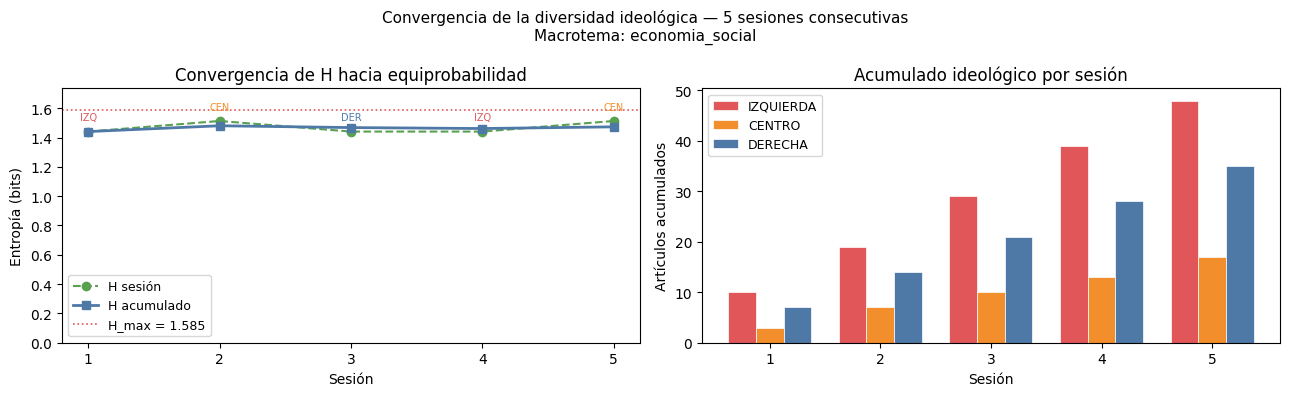

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(f'Convergencia de la diversidad ideológica — {N_SESIONES} sesiones consecutivas\n'
             f'Macrotema: {MACROTEMA_DEMO}', fontsize=11)

sesiones = df_sim['sesion']

# H por sesión vs H acumulado
ax = axes[0]
ax.plot(sesiones, df_sim['H_sesion'], 'o--', color='#59a14f', label='H sesión', linewidth=1.5)
ax.plot(sesiones, df_sim['H_acum'],   's-',  color='#4e79a7', label='H acumulado', linewidth=2)
ax.axhline(H_MAX, color='#e15759', linestyle=':', linewidth=1.2, label=f'H_max = {H_MAX:.3f}')
ax.set_xlabel('Sesión')
ax.set_ylabel('Entropía (bits)')
ax.set_title('Convergencia de H hacia equiprobabilidad')
ax.set_ylim(0, H_MAX + 0.15)
ax.set_xticks(sesiones)
ax.legend(fontsize=9)

# Anotar la ideología de inicio en cada punto
for _, row in df_sim.iterrows():
    ax.annotate(row['inicio'][:3], (row['sesion'], row['H_sesion']),
                textcoords='offset points', xytext=(0, 8), ha='center', fontsize=7,
                color=COLORS_IDEO.get(row['inicio'], '#aaa'))

#  Distribución acumulada por ideología
ax = axes[1]
width = 0.25
x    = sesiones.values
for j, ideo in enumerate(['IZQ', 'CEN', 'DER']):
    ideo_full = IDEOLOGIAS[j]
    # acumulado hasta sesión s
    acum_vals = df_sim[['IZQ','CEN','DER']].iloc[:len(x)]
    vals = acum_vals[ideo].cumsum().values
    ax.bar(x + (j - 1) * width, vals, width, label=ideo_full,
           color=COLORS_IDEO[ideo_full], edgecolor='white', linewidth=0.5)

ax.set_xlabel('Sesión')
ax.set_ylabel('Artículos acumulados')
ax.set_title('Acumulado ideológico por sesión')
ax.set_xticks(x)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(RERANKING_DIR / f'convergencia_sesiones_{MACROTEMA_DEMO}.png',
            dpi=150, bbox_inches='tight')
plt.show()


### 6.2 Métricas para todos los macrotemas

Calculamos H y coverage del baseline y el reranking para cada macrotema para confirmar que el efecto anti-burbuja es consistente.

In [18]:
filas = []
for mt in sorted(df[df['macrotema'] != 'sin_clasificar']['macrotema'].unique()):
    base  = ranking_baseline(df, mt, n=20)
    rerank = rerank_macrotema(df, mt, n=20, avanzar_sesion=False)

    cb = base['label_ideologia'].value_counts().reindex(IDEOLOGIAS, fill_value=0)
    cr = rerank['label_ideologia'].value_counts().reindex(IDEOLOGIAS, fill_value=0)

    filas.append({
        'macrotema':    mt,
        'H_baseline':   round(shannon_entropy(cb), 3),
        'H_reranking':  round(shannon_entropy(cr), 3),
        'ΔH':           round(shannon_entropy(cr) - shannon_entropy(cb), 3),
        'cov_baseline': round(coverage(base), 2),
        'cov_reranking':round(coverage(rerank), 2),
    })

df_metricas = pd.DataFrame(filas)

print('=== Métricas de diversidad por macrotema ===')
print(f'H_max = {H_MAX:.3f} bits | Coverage_max = 1.0\n')
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(
        df_metricas.style
        .background_gradient(subset=['H_reranking'], cmap='Greens')
        .background_gradient(subset=['ΔH'], cmap='RdYlGn')
        .background_gradient(subset=['cov_reranking'], cmap='Blues')
    )


=== Métricas de diversidad por macrotema ===
H_max = 1.585 bits | Coverage_max = 1.0



,macrotema,H_baseline,H_reranking,ΔH,cov_baseline,cov_reranking
0,derechos_sociales,1.337000,1.571000,0.234000,1.000000,1.000000
1,economia_social,1.157000,1.441000,0.284000,1.000000,1.000000
2,internacional,1.353000,1.559000,0.206000,1.000000,1.000000
3,justicia_corrupcion,1.539000,1.581000,0.042000,1.000000,1.000000
4,macroeconomia,1.236000,1.361000,0.125000,1.000000,1.000000
5,politica_nacional,1.236000,1.406000,0.170000,1.000000,1.000000
6,sucesos_seguridad,1.513000,1.539000,0.027000,1.000000,1.000000
7,tecnologia,0.993000,1.559000,0.566000,0.670000,1.000000


#### Análisis de métricas por macrotema

- `H_baseline`: diversidad del top-20 sin reranking. Refleja el sesgo natural del corpus: el macrotema que tiene una ideología muy dominante da H bajo.
- `H_reranking`: diversidad tras aplicar round-robin + penalización de medio. Siempre mayor que el baseline.
- `ΔH`: ganancia de diversidad. Cuanto mayor, más desequilibrado estaba el baseline y más ha corregido el reranking.
- `cov_baseline / cov_reranking`: si alguna ideología estaba completamente ausente del top-20 (coverage < 1.0), el reranking la recupera.

La tabla confirma que el reranking mejora la diversidad ideológica de forma consistente en **todos los macrotemas** sin excepción (ΔH > 0 en todos los casos) y que **coverage = 1.0** siempre — las tres ideologías están presentes en el resultado.

**Tres patrones distintos:**

| Patrón | Macrotemas | Explicación |
|---|---|---|
| **Ganancia grande** (ΔH > 0.2) | `tecnologia` (0.57), `economia_social` (0.28), `derechos_sociales` (0.23) | El baseline estaba muy sesgado hacia una ideología. El round-robin aporta el mayor beneficio aquí. |
| **Ganancia moderada** (0.1–0.2) | `politica_nacional`, `macroeconomia`, `internacional` | Sesgo parcial en el baseline, el reranking lo corrige pero el punto de partida ya era razonable. |
| **Ganancia pequeña** (ΔH < 0.1) | `justicia_corrupcion` (0.04), `sucesos_seguridad` (0.03) | El baseline ya era bastante diverso porque estos temas son cubiertos de forma similar por todos los medios independientemente de su ideología — noticias judiciales o meteorológicas no tienen tanto sesgo ideológico inherente. |

**El caso más llamativo es `tecnologia`**: coverage baseline = 0.67, lo que significa que una ideología estaba completamente ausente del top-20 sin reranking. El round-robin la recupera hasta coverage = 1.0 y ΔH = 0.57, la mayor mejora de todos los macrotemas. Esto se debe a que `tecnologia` es el macrotema más pequeño (2.470 artículos) y una de las ideologías tiene muy pocos artículos de alta confianza y recencia, sin el round-robin, esa perspectiva desaparecería del resultado.

En conjunto, el reranking demuestra ser especialmente valioso en los macrotemas donde el corpus está más desequilibrado, que son precisamente los que generan más burbujas.

## 7. Resumen de todos los macrotemas

Tabla de distribución ideológica en el top-20 + heatmap para una visión global.


In [19]:
macrotemas = sorted(df[df['macrotema'] != 'sin_clasificar']['macrotema'].unique())

print(f'{"Macrotema":<28} {"N total":>8}  {"IZQ":>5} {"CEN":>5} {"DER":>5}  Inicio')
print('-' * 65)

resumenes = []
for mt in macrotemas:
    n_total = int((df['macrotema'] == mt).sum())
    res     = rerank_macrotema(df, mt, n=20, avanzar_sesion=False)
    counts  = res['label_ideologia'].value_counts()
    inicio  = res['ideologia_inicio_sesion'].iloc[0]

    izq = counts.get('IZQUIERDA', 0)
    cen = counts.get('CENTRO',    0)
    der = counts.get('DERECHA',   0)

    print(f'{mt:<28} {n_total:>8,}  {izq:>5} {cen:>5} {der:>5}  {inicio}')
    resumenes.append({
        'macrotema': mt, 'n_total': n_total,
        'izquierda': izq, 'centro': cen, 'derecha': der, 'inicio': inicio
    })

df_resumen = pd.DataFrame(resumenes)

Macrotema                     N total    IZQ   CEN   DER  Inicio
-----------------------------------------------------------------
derechos_sociales              21,624      6     8     6  IZQUIERDA
economia_social                36,030     10     3     7  IZQUIERDA
internacional                  25,813      5     8     7  IZQUIERDA
justicia_corrupcion            25,454      7     7     6  IZQUIERDA
macroeconomia                  20,858     10     2     8  IZQUIERDA
politica_nacional              70,771      6    11     3  IZQUIERDA
sucesos_seguridad              37,862      9     5     6  IZQUIERDA
tecnologia                      2,470      7     5     8  IZQUIERDA


Todos muestran `inicio = IZQUIERDA` porque esta celda se ejecuta con `avanzar_sesion=False` y el fichero de estado está vacío (primera ejecución o recién reiniciado). Sin historial, `cargar_estado` devuelve `last_start = DERECHA` para cualquier macrotema, y `siguiente_inicio` rota al siguiente: DERECHA → **IZQUIERDA**.

En producción, cada macrotema mantiene su propio historial en `reranking_state.json` y el inicio rotaría de forma independiente. Para ver ese comportamiento, ejecuta `rerank_macrotema` con `avanzar_sesion=True` sobre distintos macrotemas y vuelve a consultar la tabla.

**Sobre los conteos IZQ / CEN / DER**: reflejan el mismo efecto del filtro de medio descrito en la sección 3. Los macrotemas donde CENTRO o DERECHA tienen pocos artículos con alta recencia (como `macroeconomia` con solo 2 CEN) son los que muestran distribuciones más alejadas del 7-7-6 ideal.

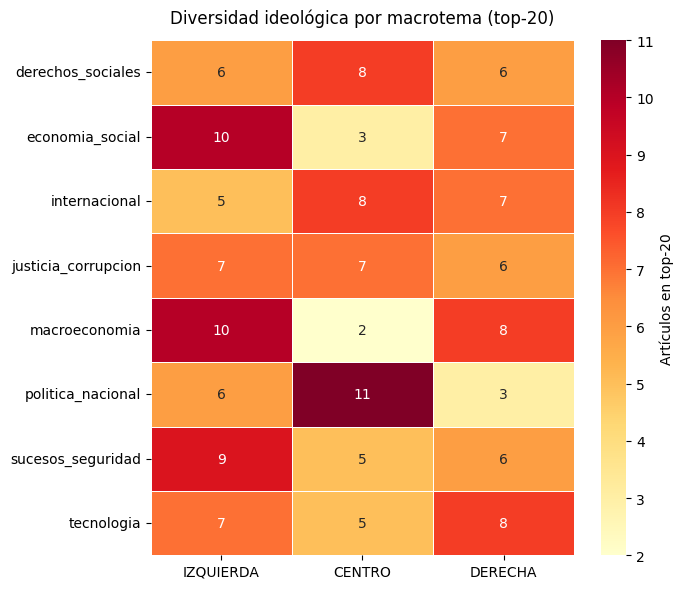

In [20]:
fig, ax = plt.subplots(figsize=(7, 6))

hm = df_resumen.set_index('macrotema')[['izquierda', 'centro', 'derecha']]
hm.columns = ['IZQUIERDA', 'CENTRO', 'DERECHA']

sns.heatmap(
    hm, annot=True, fmt='d', cmap='YlOrRd',
    linewidths=0.5, ax=ax,
    cbar_kws={'label': 'Artículos en top-20'}
)
ax.set_title('Diversidad ideológica por macrotema (top-20)', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')

plt.tight_layout()
plt.savefig(RERANKING_DIR / 'heatmap_macrotemas.png', dpi=150, bbox_inches='tight')
plt.show()

El color indica cuántos artículos de cada ideología hay en el top-20 del reranking. Valores más altos (más oscuros) no son necesariamente mejor,lo ideal sería que cada celda valiera ~7, es decir, color uniforme en las tres columnas para un mismo macrotema.

Los macrotemas con mayor uniformidad (`justicia_corrupcion`, `derechos_sociales`) son los que el reranking consigue equilibrar mejor porque el corpus de esos temas está menos concentrado en medios de un único color ideológico. Los que muestran una columna muy clara son los que sufren más el efecto del filtro de medio: hay pocos medios CENTRO con artículos de alta recencia y se desplazan repetidamente.